# Implementation of TMSE-BioCRNpyler Modules: DNA-based TMSE circuits in mammalian cells

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

The following sections highlight important features of the TMSE-BioCRNpyler modules.

Each section illustrate how to compile and simulate a DNA-based TMSE circuits that regulate gene expression in mammalian cells from Implementing Complex Nucleic Acid Circuits in Living Cells ([Sun et al. *Science Advances* 2025](https://www.science.org/doi/10.1126/sciadv.adv6512)), in BioCRNpyler using the TMSE modules. The first code block implements exisiting BioCRNpyler components, mechanisms, and mixtures seemlessly with the TMSE modules to compile a chemcial reaction network (CRN). The CRN is then simulated using BioSCRAPE at various initial conditions in the second code block. 

Specific Features:
* using specified strand exchange molecules to create a repressible assembly with `ActivatablePromoter()` and `DNAassembly()`
* incorporating additional species and reactions to the compiled CRN

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (7, 7)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 22
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.xticks(np.arange(0, 5, 1))

    # Save plot as svg
    plt.savefig(f'{figs_dir}/main_{fig_name}.svg')

# DNA-based TMSE circuits that regulate gene expression in mammalian cells simulations

![DNA-based TMSE circuits that regulate gene expression in mammalian cells](../schematics/Figure2_CRISPR.png)

**DNA-based TMSE Circuits that Regulate Gene Expression in Mammalian Cells Simulations**

*Note: Spatial separation of components and mechanisms are ignored.*

In [3]:
# Define initial DNA and Reporter DNA
sim_inputs = {'DNA_1': ['Input', 1], 'DNA_2': ['Input', 3],
              'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2],} # DNA
reporter = {'DNA_5':['Reporter', 2]} # DNA to be transcribed

# Components
step_tx = StrandExchangeMol(reporter, material_type= 'dna', transcription=True)
step_tx2 = StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse = TMSE([step_tx2.mol,step_tx.rna])

# Create additional species
Cas9 = Species("Cas9")
CRISPR = Species("CRISPR")

# Add reaction for DNA rebinding
rxn_activate = Reaction.from_massaction(inputs = [Cas9, step_tmse.signals[0]],
                                        outputs = [CRISPR],
                                        k_forward = 3e-3) 

# Create activatable DNA assembly by CRISPR
hill_parameters = {"k":1.0, "n":4, "K":20, "kleak":.00001}
# Create activatable promoter
P_activatable = ActivatablePromoter("P_activatable", activator = CRISPR, leak = True, parameters = hill_parameters)
# Create a DNA assembly "GFP"
activatable_assembly = DNAassembly(name="activatable_assembly", promoter=P_activatable, rbs="Strong", protein = 'GFP')

# Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}
# Create a transcription and translation Mechanisms
mech_tx = SimpleTranscription()
tx_mechanism= {mech_tx.mechanism_type:mech_tx}
mech_tl = SimpleTranslation()
tl_mechanism= {mech_tl.mechanism_type:mech_tl}

# Parameters
TMSE_parameters = {"kx":5e-05,
                   "krev":5e-05,
                   "krep":4e-06, 
                   "ktx":0.013, "ktl":.02,
                   } 

# Make Mixture and Compile
M_CRISPR = Mixture("Activatable_GFP", 
                 components = [step_tx.mol, step_tmse, activatable_assembly],
                 parameters = TMSE_parameters,
                 mechanisms= sd_mechanisms|tx_mechanism|tl_mechanism)

# Compile the CRN with Mixture.compile_crn
CRN_CRISPR = M_CRISPR.compile_crn()

# Add CRISPR activation rxn
CRN_CRISPR.add_reactions([rxn_activate])

# Print CRN reactions
print(CRN_CRISPR.pretty_print(show_rates = True, how_attributes = True,
                              how_materials = True, show_keys = False))

Species(N = 17) = {
rna[activatable_assembly] (@ 0),  dna[activatable_assembly] (@ 0),  rna[Signal_2] (@ 0),  rna[Reporter_2] (@ 0),  dna[Reporter_2] (@ 0),  dnarna[ReporterOut_2] (@ 0),  dna[Output_3_2] (@ 0),  dna[Output_1_2] (@ 0),  dna[Input_3] (@ 0),  dna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_3_3] (@ 0),  dna[GateOut_1_1] (@ 0),  protein[GFP] (@ 0),  Cas9 (@ 0),  CRISPR (@ 0),  
}

Reactions (9) = [
0. dna[Reporter_2] --> dna[Reporter_2]+rna[Reporter_2]
 Kf=k_forward * dna_Reporter_2
  k_forward=0.013

1. dna[Gate_1_2]+dna[Input_1] <--> dna[Output_1_2]+dna[GateOut_1_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Input_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_1_1
  k_forward=5e-05
  k_reverse=5e-05

2. dna[Gate_3_2]+dna[Input_3] <--> dna[Output_3_2]+dna[GateOut_3_3]
 Kf=k_forward * dna_Gate_3_2 * dna_Input_3
 Kr=k_reverse * dna_Output_3_2 * dna_GateOut_3_3
  k_forward=5e-05
  k_reverse=5e-05

3. dna[Output_1_2]+rna[Reporter_2] --> rna[Signal_2]+dnarn

### Simulated using BioSCRAPE

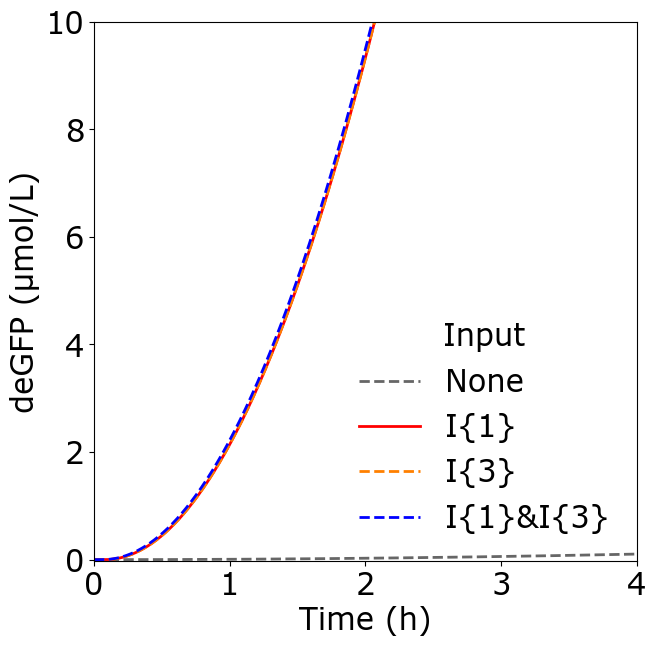

In [4]:
# Simulate
try:
    # Input templates
    IN1 = [0, 1, 0, 1]
    IN3 = [0, 0, 1, 1]

    idx_conditions = {'None':[[0.4,0.4,0.4], '--'],
                      'I{1}': [[1,0,0],'-'],
                      'I{3}': [[1,0.5,0],'--'],
                      'I{1}&I{3}': [[0,0,1],'--']}

    for IN1_conc, IN3_conc, key in zip(IN1, IN3, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': IN1_conc*100, 'dna_Input_3': IN3_conc*100,
                                      'dna_Gate_1_2':100, 'dna_Gate_3_2':100, 
                                      'dna_Reporter_2':150,
                                      'dna_activatable_assembly':5,
                                      'Cas9':5}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_CRISPR.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                      initial_condition_dict = initial_concentration_dict)

        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2,
                 linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='deGFP (μmol/L)',ymax = 10, fig_name= 'Figure2_CRISPR')    

# Computing environment

In [5]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

